# Analysis for the Project: Debt-Based License Suspension

## The Main Questions:
- What are the reasons for license suspensions? [Jassim]
- What % are not falling under safety related? [Rachel, Alberto]
- What % are debt based? [Sarah]
- How many people lose their license over nothing dangerous? [Yuan, Ethan]

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

/Users/rachelyoung/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/rachelyoung/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


# Classified Data

In [5]:
classified = pd.read_csv("Classifications_V3.csv")
classified

,Description,count,dangerous,debt_based,undefined
0,PAYMENT DEFAULT,180091,FALSE,True,False
1,Three Surchargeable Events,162663,TRUE,False,False
2,Major Disqualification,121275,TRUE,False,False
3,Reciprocal Suspension,62833,UNCODED,False,True
4,WARRANT,60608,FALSE,False,False
...,...,...,...,...,...
198,RDR __ RESUSP DRUGS,1,FALSE,False,False
199,CHEMICAL TEST REFUSAL,1,FALSE,False,False
200,CHEAT ON CDL EXAM,1,FALSE,False,False
201,B22 - DRIVING WHILE CANCELED,1,FALSE,False,False


## Tableau/Visualization Dataset


In [3]:
#import reinstated data

#Choose the columns to be analyzed
col_ri = ['Year Reinstated','Description', 'Term', 'Days Sus/Rev']

#Read the CSV files 
ri_2020 = pd.read_csv("Reinstatement_information_2020.csv", usecols=col_ri, dtype=str)
ri_2021 = pd.read_csv("Reinstatement_information_2021.csv", usecols=col_ri, dtype=str)
ri_2022 = pd.read_csv("Reinstatement_information_2022 Jan-Nov.csv", usecols=col_ri, dtype=str)

#Combine the csv files
ri = pd.concat([ri_2020, ri_2021, ri_2022], axis=0)

#Insert a column that labels the data points as the dataset they're from
ri = ri.assign(Dataset = 'Reinstated')
cols = ri.columns.tolist()
cols = cols[-1:] + cols[:-1]
ri = ri[cols]

ri= ri.rename(columns = {"Days Sus/Rev": "Days_suspended", "Year Reinstated": "Year"})
ri

,Dataset,Year,Description,Term,Days_suspended
0,Reinstated,2020,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072
1,Reinstated,2020,PROPERTY DAMAGE CLAIM,Indefinite,714
2,Reinstated,2020,NRVC Withdrawal,Indefinite,1191
3,Reinstated,2020,NRVC Withdrawal,Indefinite,924
4,Reinstated,2020,94C35 __ PRESENT WITH HEROIN,Definite,365
...,...,...,...,...,...
27887,Reinstated,2022,Three Surchargeable Events,Indefinite,1431
27888,Reinstated,2022,UNINSURED MOTOR VEHICLE c90 §34J,Definite,60
27889,Reinstated,2022,PAYMENT DEFAULT,Indefinite,66
27890,Reinstated,2022,COMPLAINT FRAUDULENT LICENSE/ID,Indefinite,180


In [4]:
# Read the csv's 

#Choose the columns to be analyzed
col_si = ['Year','Description', 'Term', 'Days Sus/Rev']

#Read the CSV files 
si_2020 = pd.read_csv("Suspension_information_2020.csv", usecols=col_si, dtype=str)
si_2021 = pd.read_csv("Suspension_information_2021.csv", usecols=col_si, dtype=str)
si_2022 = pd.read_csv("Suspension_information_2022 Jan - Nov.csv", usecols=col_si, dtype=str)

#Combine the csv files
si = pd.concat([si_2020, si_2021, si_2022], axis=0)

#Insert a column that labels the data points as the dataset they're from
si = si.assign(Dataset = 'Suspensions Initiated')
col_si = si.columns.tolist()
col_si = col_si[-1:] + col_si[:-1]
si = si[col_si]

si = si.rename(columns = {"Days Sus/Rev": "Days_suspended"})
si


,Dataset,Year,Description,Term,Days_suspended
0,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,2920
1,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,730
2,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,2920
3,Suspensions Initiated,2020,Ignition Interlock Device,Indefinite,INDEFINITE
4,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,730
...,...,...,...,...,...
114595,Suspensions Initiated,2022,COMPLAINT REGULATORY,Indefinite,10
114596,Suspensions Initiated,2022,Operating Under Influence (OUI),Definite,45
114597,Suspensions Initiated,2022,Operating Under Influence (OUI),Definite,45
114598,Suspensions Initiated,2022,B26 - Driving while suspended,Definite,60


In [6]:
col_current = ['Description', 'Term', 'Days Sus/Rev']

current = pd.read_csv("currently_suspended_information.csv", usecols=col_current, dtype=str)

#Insert a column that labels the data points as the dataset they're from
current = current.assign(Dataset = 'Currently suspended')
current = current.assign(Year = 2022)
col_current = current.columns.tolist()
col_current = col_current[-2:] + col_current[:-2]
current = current[col_current]

current = current.rename(columns = {"Days Sus/Rev": "Days_suspended"})
current


,Dataset,Year,Description,Term,Days_suspended
0,Currently suspended,2022,COURT DEFAULT,Indefinite,INDEFINITE
1,Currently suspended,2022,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
2,Currently suspended,2022,Ignition Interlock Device,Indefinite,INDEFINITE
3,Currently suspended,2022,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
4,Currently suspended,2022,FSU __ 5 SURCHARGE EVENTS,Indefinite,INDEFINITE
...,...,...,...,...,...
693095,Currently suspended,2022,Massachusetts Disqualification,Lifetime,INDEFINITE
693096,Currently suspended,2022,Chemical Test Refusal,Definite,1095
693097,Currently suspended,2022,Chemical Test Refusal,Definite,180
693098,Currently suspended,2022,Massachusetts Disqualification,Definite,365


In [10]:
tableau_data = pd.concat([ri, si, current], axis=0)
tableau_data

,Dataset,Year,Description,Term,Days_suspended
0,Reinstated,2020,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072
1,Reinstated,2020,PROPERTY DAMAGE CLAIM,Indefinite,714
2,Reinstated,2020,NRVC Withdrawal,Indefinite,1191
3,Reinstated,2020,NRVC Withdrawal,Indefinite,924
4,Reinstated,2020,94C35 __ PRESENT WITH HEROIN,Definite,365
...,...,...,...,...,...
693095,Currently suspended,2022,Massachusetts Disqualification,Lifetime,INDEFINITE
693096,Currently suspended,2022,Chemical Test Refusal,Definite,1095
693097,Currently suspended,2022,Chemical Test Refusal,Definite,180
693098,Currently suspended,2022,Massachusetts Disqualification,Definite,365


In [11]:
tableau_data2 = pd.merge(tableau_data, classified, on='Description', how='left')
tableau_data2.drop("count", axis = 1)

,Dataset,Year,Description,Term,Days_suspended,dangerous,debt_based,undefined
0,Reinstated,2020,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072,FALSE,True,False
1,Reinstated,2020,PROPERTY DAMAGE CLAIM,Indefinite,714,FALSE,False,False
2,Reinstated,2020,NRVC Withdrawal,Indefinite,1191,TRUE,False,False
3,Reinstated,2020,NRVC Withdrawal,Indefinite,924,TRUE,False,False
4,Reinstated,2020,94C35 __ PRESENT WITH HEROIN,Definite,365,FALSE,False,False
...,...,...,...,...,...,...,...,...
1184077,Currently suspended,2022,Massachusetts Disqualification,Lifetime,INDEFINITE,TRUE,False,False
1184078,Currently suspended,2022,Chemical Test Refusal,Definite,1095,FALSE,False,False
1184079,Currently suspended,2022,Chemical Test Refusal,Definite,180,FALSE,False,False
1184080,Currently suspended,2022,Massachusetts Disqualification,Definite,365,TRUE,False,False


In [39]:
tableau_data2["dangerous"] = tableau_data2["dangerous"].astype("object")

In [43]:
from pathlib import Path  
filepath = Path('/Users/rachelyoung/Downloads/tableau_data_v3.csv')  
filepath.parent.mkdir(parents=True, exist_ok=True)  
tableau_data2.to_csv(filepath)

In [42]:
tableau_data2.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1184082 entries, 0 to 1184081
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   Dataset         1184082 non-null  object
 1   Year            1184082 non-null  object
 2   Description     1184082 non-null  object
 3   Term            1166463 non-null  object
 4   Days_suspended  1184082 non-null  object
 5   count           1184082 non-null  int64 
 6   dangerous       1184082 non-null  object
 7   debt_based      1184082 non-null  bool  
 8   undefined       1184082 non-null  bool  
dtypes: bool(2), int64(1), object(6)
memory usage: 74.5+ MB


## 1. What are the reasons for license suspension?

In [7]:
ri['Description'].nunique()

156

In [8]:
si['Description'].nunique()

157

In [9]:
current['Description'].nunique()

162

# Debt-Based by Year

## Suspensions Initiated


In [16]:
#merge with classifications 
graph_si = pd.merge(si, classified, on='Description', how='left')

cols_si= ["Dataset", "Days_suspended", "count", "undefined"]
graph_si = graph_si.drop(cols_si, axis =1)
graph_si.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 342783 entries, 0 to 342782
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Year         342783 non-null  object
 1   Description  342783 non-null  object
 2   Term         336103 non-null  object
 3   dangerous    342783 non-null  object
 4   debt_based   342783 non-null  bool  
dtypes: bool(1), object(4)
memory usage: 10.8+ MB


In [24]:
year_groups = graph_si.groupby('Year')['debt_based'].agg(['count', 'sum']).reset_index()
year_groups["percent"] = round((year_groups["sum"]/year_groups["count"])*100, 2)
year_groups

,Year,count,sum,percent
0,2020,116841,21142,18.09
1,2021,111342,20052,18.01
2,2022,114600,23160,20.21


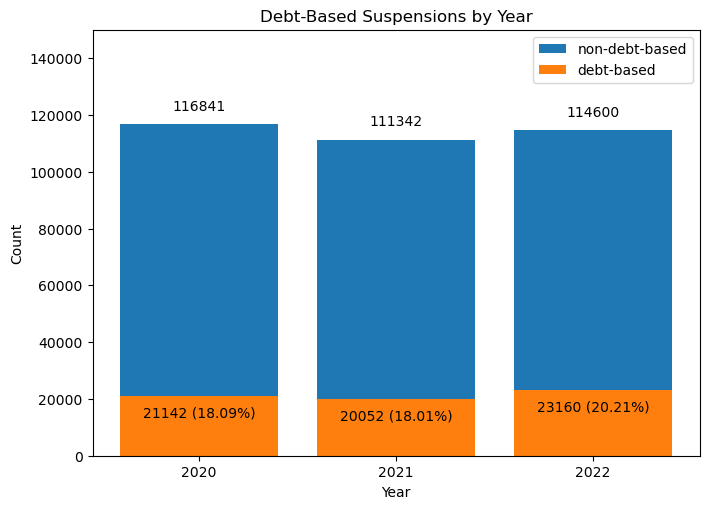

In [143]:
plt.figure(figsize=(7, 5))
plt.title('Debt-Based Suspensions by Year')

plt.bar(year_groups['Year'], year_groups['count'], label='non-debt-based')
plt.bar(year_groups['Year'], year_groups['sum'], label='debt-based')

plt.xticks(year_groups['Year'])

for i, v in zip(year_groups['Year'], year_groups['count']):
    plt.annotate(
        f'{round(v, 2)}',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v, p in zip(year_groups['Year'], year_groups['sum'], year_groups['percent']):
    plt.annotate(
        f'{round(v, 2)} ({round(p, 2)}%)',
        (i, v),
        textcoords="offset points",
        xytext=(0, -15),
        ha='center'
    )
plt.ylim(0, 150000)
plt.tight_layout()

plt.xlabel('Year')
plt.ylabel('Count')

#plt.savefig(img_path / 'safe_debtbased_suspensions.png')
plt.legend()
plt.show()

In [51]:
si_road = graph_si.groupby(['Year', 'dangerous']).size().unstack(fill_value=0)
si_road["total"] = si_road.sum(axis=1)
si_road = si_road.reset_index()
si_road

dangerous,Year,FALSE,TRUE,UNCODED,total
0,2020,31509,79563,5769,116841
1,2021,30416,60557,20369,111342
2,2022,35767,58713,20120,114600


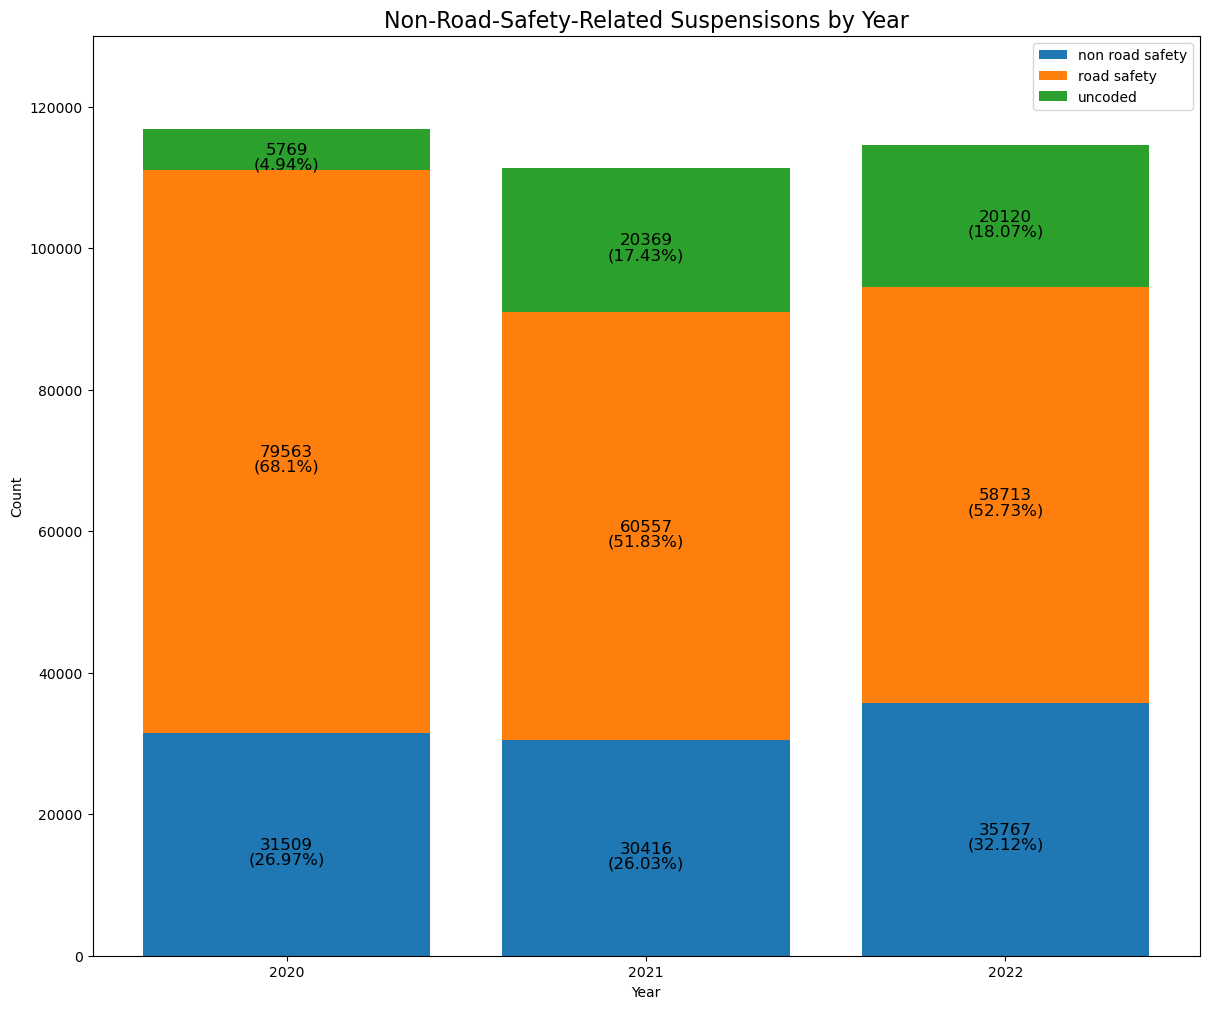

In [158]:
plt.figure(figsize=(12, 10))
plt.title('Non-Road-Safety-Related Suspensisons by Year', fontsize=16)


#plt.bar(si_road['Year'], si_road['total'])
bars1 = plt.bar(si_road['Year'], si_road['FALSE'], label='non road safety')
bars2 = plt.bar(si_road['Year'], si_road['TRUE'], bottom = si_road['FALSE'], label='road safety')
bars3 = plt.bar(si_road['Year'], si_road['UNCODED'], bottom= si_road['FALSE'] + si_road['TRUE'], label='uncoded')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        plt.annotate('{}'.format(round(height, 2)),
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2+ bar.get_y()),  # Center of each bar
                     xytext=(0, 5),  # Offset for the xytext
                     textcoords="offset points",
                     ha='center', va='top',
                     fontsize=12) 
        

total_year = si_road["total"]
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        year_index = bar.get_x()
        year = si_road['Year'].iloc[int(year_index)]
        total = total_year.iloc[int(year_index)]
        percentage = round((height / total) * 100, 2)
        plt.annotate(f"({percentage}%)",
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height() /2 + bar.get_y()),  # Center of each bar
                     xytext=(0, -11),  # Offset for the xytext
                     textcoords="offset points",
                     ha='center', va='center',
                    fontsize=12) 
        


plt.ylim(0, 130000)
plt.tight_layout()

plt.xlabel('Year')
plt.ylabel('Count')

#plt.savefig(img_path / 'safe_debtbased_suspensions.png')
plt.legend()
plt.show()